Data Loading

In [37]:

import pandas as pd
import math
import random

filename = "cities.csv"

cities = pd.read_csv(filename)
print(cities.head())

def distance(a,b):
    return math.hypot(a["X"]-b["X"], a["Y"]-b["Y"])

def route_distance(route,cities):
    total=0
    for i in range(len(route)):
        c1=cities.iloc[route[i]]
        c2=cities.iloc[route[(i+1)%len(route)]]
        total+=distance(c1,c2)
    return total

def random_route(n):
    r=list(range(n))
    random.shuffle(r)
    return r


     City          X          Y
0  City_1  37.454012  95.071431
1  City_2  73.199394  59.865848
2  City_3  15.601864  15.599452
3  City_4   5.808361  86.617615
4  City_5  60.111501  70.807258


Simulated_Annealing



In [38]:

import math, random

def simulated_annealing(cities):
    route=random_route(len(cities))
    best=route[:]
    current=route_distance(route,cities)
    best_cost=current
    temp=200
    history=[]

    while temp>1:
        new=route[:]
        i,j=random.sample(range(len(route)),2)
        new[i],new[j]=new[j],new[i]
        new_cost=route_distance(new,cities)

        if new_cost<current or random.random()<math.exp((current-new_cost)/temp):
            route=new
            current=new_cost

        if current<best_cost:
            best=route[:]
            best_cost=current

        history.append(best_cost)
        temp*=0.95

    print("SA Distance:",best_cost)
    return best,best_cost,history

# simulated_annealing(cities)


Genetic Algorithm

In [44]:
import random

def tournament(pop, cities):
    return min(random.sample(pop, 3), key=lambda r: route_distance(r, cities))

def crossover(parent1, parent2):
    n = len(parent1)
    start, end = sorted(random.sample(range(n), 2))

    child = [-1] * n
    child[start:end] = parent1[start:end]

    remaining = [city for city in parent2 if city not in child]

    j = 0
    for i in range(n):
        if child[i] == -1:
            child[i] = remaining[j]
            j += 1

    return child


def genetic_algorithm(cities, pop_size=20, generations=50, mutation_rate=0.1):

    # Initial population
    population = [random_route(len(cities)) for _ in range(pop_size)]

    # Store best distance of every generation
    history = []

    for _ in range(generations):

        # Sort by fitness (shorter distance is better)
        population.sort(key=lambda r: route_distance(r, cities))

        # Record convergence
        history.append(route_distance(population[0], cities))

        # Elitism
        new_population = population[:2]

        while len(new_population) < pop_size:

            p1 = tournament(population, cities)
            p2 = tournament(population, cities)

            child = crossover(p1, p2)

            # Mutation
            if random.random() < mutation_rate:
                i, j = random.sample(range(len(child)), 2)
                child[i], child[j] = child[j], child[i]

            new_population.append(child)

        population = new_population

    # Final best solution
    population.sort(key=lambda r: route_distance(r, cities))
    best_route = population[0]
    best_distance = route_distance(best_route, cities)

    print("GA Distance:", best_distance)

    return best_route, best_distance, history

#genetic_algorithm(cities)

GA Distance: 1559.0277699600822


([39,
  24,
  40,
  37,
  43,
  20,
  29,
  28,
  7,
  47,
  19,
  31,
  42,
  49,
  36,
  5,
  45,
  33,
  32,
  10,
  15,
  18,
  2,
  48,
  35,
  17,
  25,
  38,
  6,
  44,
  46,
  1,
  8,
  30,
  9,
  23,
  12,
  26,
  34,
  21,
  16,
  0,
  27,
  4,
  41,
  11,
  13,
  3,
  22,
  14],
 1559.0277699600822,
 [2357.775686758481,
  2157.980850469165,
  2125.6813066462305,
  2125.6813066462305,
  2077.9586406616004,
  2077.9586406616004,
  1982.2538147227258,
  1982.2538147227258,
  1979.6772998714775,
  1977.184074568958,
  1976.784944299466,
  1940.862507832923,
  1940.862507832923,
  1857.6775700628157,
  1842.549541934976,
  1842.549541934976,
  1842.549541934976,
  1768.6676304989733,
  1768.6676304989733,
  1764.475456360362,
  1742.8012594910315,
  1742.8012594910315,
  1742.8012594910315,
  1742.8012594910315,
  1742.8012594910315,
  1709.420899822035,
  1693.0850340697612,
  1670.17589309606,
  1636.7269477169555,
  1636.7269477169555,
  1636.7269477169555,
  1625.695241843983

Convergence Comparison

SA Distance: 1710.0517926027358
GA Distance: 1603.5850293772662


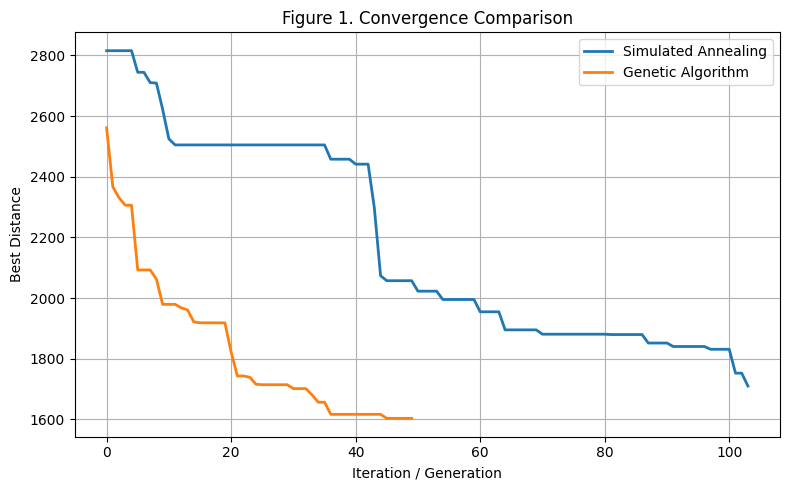

In [45]:
import matplotlib.pyplot as plt

# Run both algorithms
_, _, sa_history = simulated_annealing(cities)
_, _, ga_history = genetic_algorithm(cities)

# Figure 1: Plot convergence
plt.figure(figsize=(8,5))

plt.plot(sa_history,
         label="Simulated Annealing",
         linewidth=2)

plt.plot(ga_history,
         label="Genetic Algorithm",
         linewidth=2)

plt.xlabel("Iteration / Generation")
plt.ylabel("Best Distance")
plt.title("Figure 1. Convergence Comparison")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("figure1_convergence_comparison.png", dpi=300)

plt.show()

Performance Evaluation

In [41]:
import time
import pandas as pd

results = []

for size in [10, 20, 30, 40, 50]:
    subset = cities.iloc[:size].reset_index(drop=True)

    # Simulated Annealing
    start = time.time()
    _, sa_cost, _ = simulated_annealing(subset)
    sa_time = time.time() - start

    # Genetic Algorithm
    start = time.time()
    _, ga_cost, _ = genetic_algorithm(subset)   # unpack 3 values
    ga_time = time.time() - start

    results.append([
        size,
        round(sa_cost, 2),
        round(ga_cost, 2),
        round(sa_time, 4),
        round(ga_time, 4)
    ])

table3 = pd.DataFrame(
    results,
    columns=[
        "Cities",
        "SA Best",
        "GA Best",
        "SA Time (s)",
        "GA Time (s)"
    ]
)

print(table3)

table3.to_csv("performance_results.csv", index=False)

SA Distance: 356.678490461366
GA Distance: 356.678490461366
SA Distance: 677.0543946930684
GA Distance: 556.1470485075312
SA Distance: 984.1205628363781
GA Distance: 843.8556548996003
SA Distance: 1478.5756265430327
GA Distance: 1138.1418762297762
SA Distance: 1931.3048839711898
GA Distance: 1599.6496937343247
   Cities  SA Best  GA Best  SA Time (s)  GA Time (s)
0      10   356.68   356.68       0.0863       5.3365
1      20   677.05   556.15       0.2020      11.7195
2      30   984.12   843.86       0.2784      16.9891
3      40  1478.58  1138.14       0.3952      23.6364
4      50  1931.30  1599.65       0.4319      29.7606


Graphs

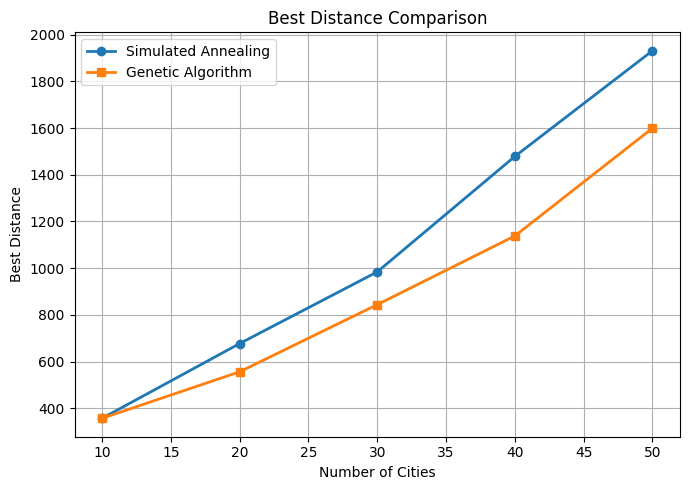

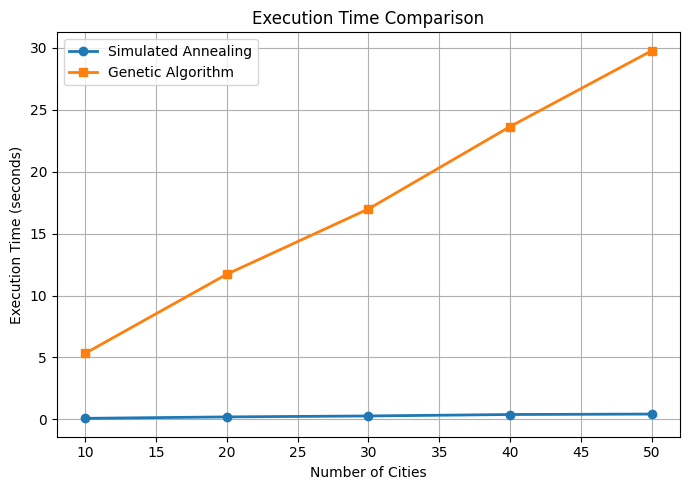

In [42]:
import matplotlib.pyplot as plt

# Figure 2: Best Distance

plt.figure(figsize=(7,5))

plt.plot(table3["Cities"],
         table3["SA Best"],
         marker="o",
         linewidth=2,
         label="Simulated Annealing")

plt.plot(table3["Cities"],
         table3["GA Best"],
         marker="s",
         linewidth=2,
         label="Genetic Algorithm")

plt.xlabel("Number of Cities")
plt.ylabel("Best Distance")
plt.title("Best Distance Comparison")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.savefig("best_distance.png", dpi=300)
plt.show()

# Figure 3: Execution Time

plt.figure(figsize=(7,5))

plt.plot(table3["Cities"],
         table3["SA Time (s)"],
         marker="o",
         linewidth=2,
         label="Simulated Annealing")

plt.plot(table3["Cities"],
         table3["GA Time (s)"],
         marker="s",
         linewidth=2,
         label="Genetic Algorithm")

plt.xlabel("Number of Cities")
plt.ylabel("Execution Time (seconds)")
plt.title("Execution Time Comparison")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.savefig("execution_time.png", dpi=300)
plt.show()

Statistical Analysis

In [43]:

from scipy.stats import ttest_ind

t,p=ttest_ind(table3["SA Best"],table3["GA Best"])

print("t statistic:",t)
print("p value:",p)

if p<0.05:
    print("Significant difference between algorithms.")
else:
    print("No significant difference.")


t statistic: 0.5236522160481482
p value: 0.6147127647517383
No significant difference.
